In [18]:
%pylab inline
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
rc_params = {'backend': 'pdf',
             'axes.labelsize': 24,
             'axes.titlesize': 32,
             'font.size': 18,
             'legend.fontsize': 18,
             'xtick.labelsize': 24,
             'ytick.labelsize': 24,
            }
plt.rcParams.update({
    "text.usetex": False,
    "text.latex.preamble": r"\usepackage{amsfonts}\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}",  
    "font.family": "serif"
})

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [19]:
import numpy as np
from stochaxtic import OmegaIntegrator

# BBH：GWTC-5 质量分布 + Madau-Dickinson
oi  = OmegaIntegrator("uniform", "madau_dickinson_timedelay",
                      rate_kwargs={"R0": 15.9}, waveform="IMRPhenomXAS", freqs=np.arange(5, 4096+0.25, 0.25))
res = oi.run(n_rep=8)                 # 约 10 s

res.freqs        
res.omega        
res.omega_err   
res.save("bns.npz")

setup: kernel + proposal in 0.7 s, R_tot = 2.49e+04 events/yr in z = [0.2, 10.0]


/Users/haowenzhong/Claudecode/SGWB_toolbox/StochAXtic/stochaxtic/waveforms.py:61: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


KeyboardInterrupt: 

(2e-12, 2e-10)

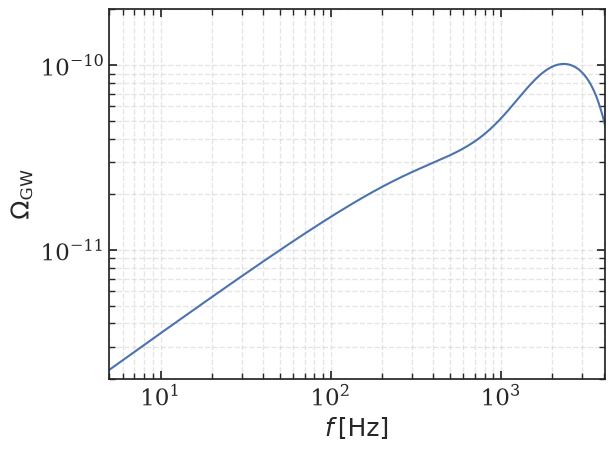

In [36]:
plt.loglog(res.freqs, res.omega, label=r"$\Omega_\mathrm{GW}$")
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 4096)
plt.ylim(2e-12, 2e-10)

In [2]:
import time, numpy as np, jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
numpyro.enable_x64()
from stochaxtic.fast_omega import FastOmega

freqs = np.geomspace(5, 1024, 1000)
fo = FastOmega(freqs=freqs, m_tot_range=(6, 700), n_u=3, n_phi=1)
omega = fo.make("bpl_double_gaussian", "madau_dickinson")

truth = dict(alpha_m_1=1.5754, R0=15.9)
Omega_truth = omega({"alpha_m_1": truth["alpha_m_1"]}, {"R0": truth["R0"]})
sigma = 0.01 * Omega_truth

st = time.time()
data  = Omega_truth + sigma * np.random.default_rng(1).standard_normal(len(freqs))
et = time.time()
print(f"模拟数据生成耗时：{et-st:.3f} s")


/Users/haowenzhong/miniforge3/envs/sgwb/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/haowenzhong/Claudecode/SGWB_toolbox/StochAXtic/stochaxtic/waveforms.py:58: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


FastOmega: J table (2461 x 121, IMRPhenomXAS) in 1.0 s; grids lnM 953, z 444, lnq 121, lnf 1066
模拟数据生成耗时：0.025 s


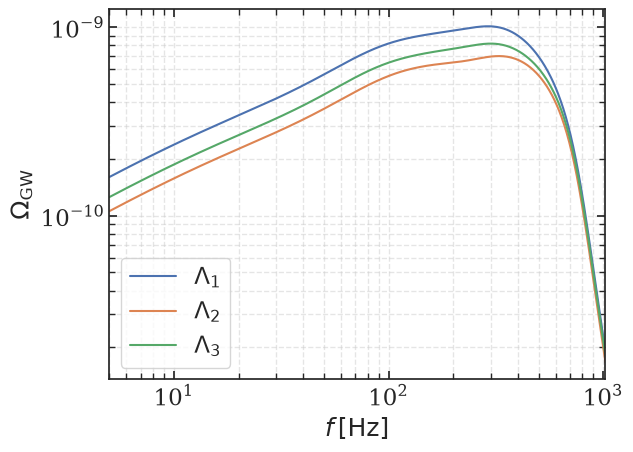

In [3]:
Lambda_1 = dict(alpha_m_1=1.5754, R0=15.9, alpha=2.7, beta=5.6, zp=2.0)
Lambda_2 = dict(alpha_m_1=1.5754, R0=15.9, alpha=2.3, beta=5.3, zp=1.8)
Lambda_3 = dict(alpha_m_1=1.5754, R0=17.9, alpha=2.1, beta=6.5, zp=2.3)
Omega_Lambda_1 = omega({"alpha_m_1": Lambda_1["alpha_m_1"]}, {"R0": Lambda_1["R0"],"alpha": Lambda_1["alpha"], "beta": Lambda_1["beta"], "zp": Lambda_1["zp"]})
Omega_Lambda_2 = omega({"alpha_m_1": Lambda_2["alpha_m_1"]}, {"R0": Lambda_2["R0"],"alpha": Lambda_2["alpha"], "beta": Lambda_2["beta"], "zp": Lambda_2["zp"]})
Omega_Lambda_3 = omega({"alpha_m_1": Lambda_3["alpha_m_1"]}, {"R0": Lambda_3["R0"],"alpha": Lambda_3["alpha"], "beta": Lambda_3["beta"], "zp": Lambda_3["zp"]})
plt.loglog(freqs, Omega_Lambda_1, label=r"$\Lambda_1$")
plt.loglog(freqs, Omega_Lambda_2, label=r"$\Lambda_2$")
plt.loglog(freqs, Omega_Lambda_3, label=r"$\Lambda_3$")
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 1024)
plt.legend()


In [17]:
import time, numpy as np, jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
numpyro.enable_x64()
from stochaxtic.fast_omega import FastOmega

fo_XPHM = FastOmega(freqs=np.arange(5, 4096 + 0.25, 0.25),      # 频点多少几乎不影响速度
               waveform="IMRPhenomXPHM", spins="precessing",
               a_max=0.05, x_ref=3e-4,
               m_tot_range=(1.8, 6.0), q_min=0.3, n_q=41,   # BNS 网格，要覆盖你的布居
               n_proc=4)
omega_XPHM = fo_XPHM.make("uniform", "madau_dickinson_timedelay")

fo_XAS = FastOmega(freqs=np.arange(5, 4096 + 0.25, 0.25),      # 频点多少几乎不影响速度
               waveform="IMRPhenomXAS", spins='aligned',
               a_max=0.05, x_ref=3e-4,
               m_tot_range=(1.8, 6.0), q_min=0.3, n_q=41,   # BNS 网格，要覆盖你的布居
               n_proc=4)
omega_XAS  = fo_XAS.make("uniform", "madau_dickinson_timedelay")

om_XPHM = omega_XPHM({}, {"R0": 23.4}, {"alpha_chi": 1.6, "beta_chi": 4.1, "zeta": 0.66, "sigma_t": 1.5})
om_XAS = omega_XAS({}, {"R0": 23.4}, {"alpha_chi": 1.6, "beta_chi": 4.1, "zeta": 0.66, "sigma_t": 1.5})

FastOmega: table loaded from /Users/haowenzhong/.cache/stochaxtic/jtable_IMRPhenomXPHM_3f677244acfa6460.npz
FastOmega: IMRPhenomXPHM, spins=precessing, tides=False: 5248 table columns, rank 15; grids lnM 242, z 444, lnq 41, lnf 1343; setup 7.9 s
FastOmega: building the IMRPhenomXAS table: 5248 spin/q columns x 1 kappa nodes, 987 frequencies each ...
FastOmega: table built in 5 s, cached at /Users/haowenzhong/.cache/stochaxtic/jtable_IMRPhenomXAS_38a74a62bfe4d126.npz
FastOmega: IMRPhenomXAS, spins=aligned, tides=False: 5248 table columns, rank 12; grids lnM 242, z 444, lnq 41, lnf 1343; setup 14.4 s


(5, 4096)

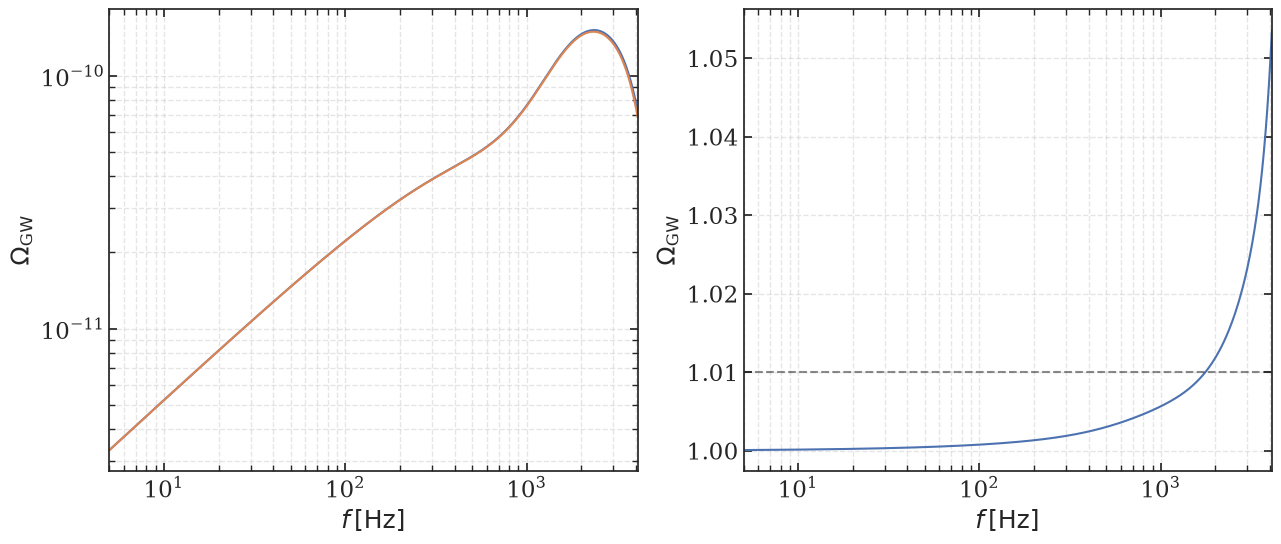

In [21]:
plt.figure(figsize=(15, 6))
plt.subplot(121)
plt.loglog(fo_XPHM.freqs, om_XPHM, label=r"$\Omega_\mathrm{GW}$ (XPHM)")
plt.loglog(fo_XAS.freqs, om_XAS, label=r"$\Omega_\mathrm{GW}$ (XAS)")
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 4096)
plt.subplot(122)
plt.semilogx(fo_XPHM.freqs, om_XPHM / om_XAS, label=r"$\Omega_\mathrm{GW}$ (XPHM) / $\Omega_\mathrm{GW}$ (XAS)")
plt.axhline(1.01, color='k', linestyle='--', alpha=0.5)
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 4096)

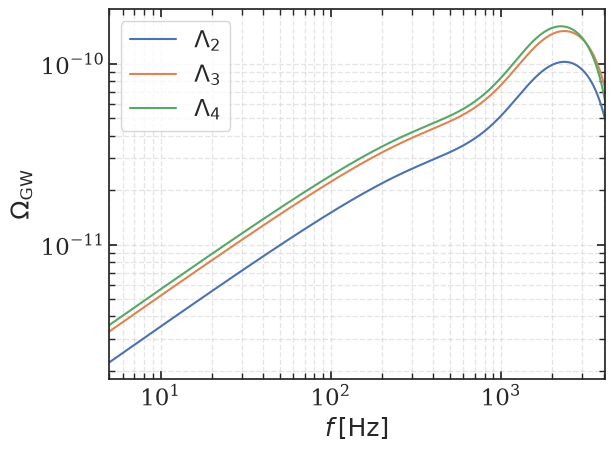

In [15]:
om_lambda2 = omega({}, {"R0": 15.8}, {"alpha_chi": 1.8, "beta_chi": 3.1, "zeta": 0.66, "sigma_t": 1.5})
om_lambda3 = omega({}, {"R0": 23.4}, {"alpha_chi": 1.2, "beta_chi": 4.1, "zeta": 0.66, "sigma_t": 1.5})
om_lambda4 = omega({"m1_min": 1.5, "m_max": 2.0}, {"R0": 23.4}, {"alpha_chi": 1.2, "beta_chi": 4.1, "zeta": 0.66, "sigma_t": 1.5})
plt.loglog(fo.freqs, om_lambda2, label=r"$\Lambda_2$")
plt.loglog(fo.freqs, om_lambda3, label=r"$\Lambda_3$")
plt.loglog(fo.freqs, om_lambda4, label=r"$\Lambda_4$")
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 4096)
plt.legend()

In [74]:
mS = np.random.normal(1.5754, 0.5, 4000)
rS = np.random.normal(15.9, 1.0, 4000)
omega   = fo.make("bpl_double_gaussian", "madau_dickinson")        # jitted 单个 Λ → Ω(f)

In [75]:
def batched_omega(m, r, batch_size=200):
    one = lambda m, r: omega({"alpha_m_1": m}, {"R0": r})   # omega 要的是两个 dict
    n = m.shape[0]
    mb = m.reshape(n // batch_size, batch_size)
    rb = r.reshape(n // batch_size, batch_size)
    out = jax.lax.map(lambda a: jax.vmap(one)(*a), (mb, rb))  # 各 batch 依次算，batch 内部 vmap
    return out.reshape(n, -1)

batched = jax.jit(batched_omega, static_argnames="batch_size")
Om = batched(mS, rS)      # (4000, 400)

In [36]:
Om.shape

(4000, 4077)

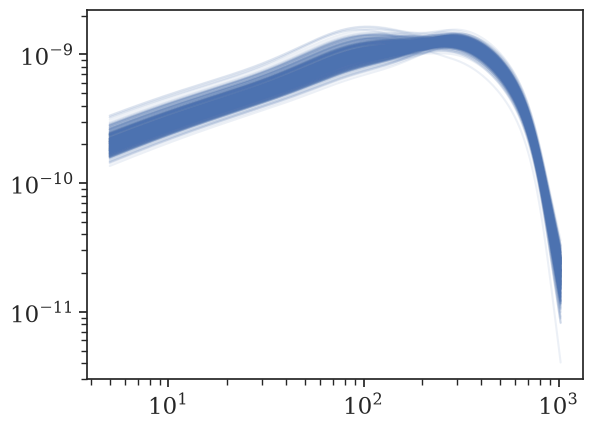

In [76]:
for i in range(400):
    plt.loglog(fo.freqs, Om[i, :], color="C0", alpha=0.1)

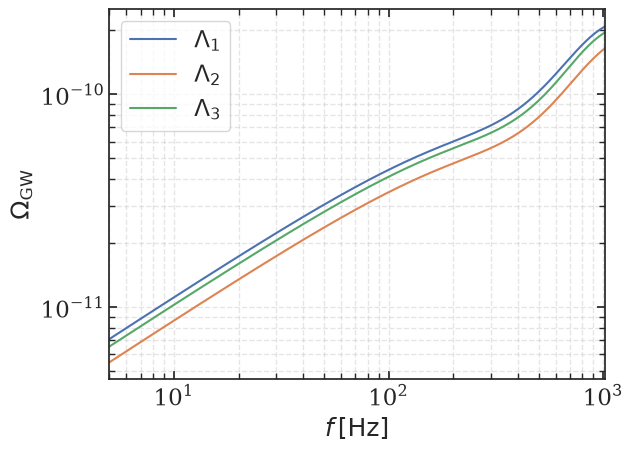

In [4]:
omega = fo.make("uniform", "madau_dickinson_timedelay")
Lambda_1 = dict(m1_min=1.0, m2_min=1.0, m_max=2.5, R0=15.9, alpha=2.7, beta=5.6, zp=2.0)
Lambda_2 = dict(m1_min=1.0, m2_min=1.0, m_max=2.5, R0=15.9, alpha=2.3, beta=5.3, zp=1.8)
Lambda_3 = dict(m1_min=1.0, m2_min=1.0, m_max=2.5, R0=17.9, alpha=2.1, beta=6.5, zp=2.3)
Omega_Lambda_1 = omega({"m1_min": Lambda_1["m1_min"], "m2_min": Lambda_1["m2_min"], "m_max": Lambda_1["m_max"]}, {"R0": Lambda_1["R0"],"alpha": Lambda_1["alpha"], "beta": Lambda_1["beta"], "zp": Lambda_1["zp"]})
Omega_Lambda_2 = omega({"m1_min": Lambda_2["m1_min"], "m2_min": Lambda_2["m2_min"], "m_max": Lambda_2["m_max"]}, {"R0": Lambda_2["R0"],"alpha": Lambda_2["alpha"], "beta": Lambda_2["beta"], "zp": Lambda_2["zp"]})
Omega_Lambda_3 = omega({"m1_min": Lambda_3["m1_min"], "m2_min": Lambda_3["m2_min"], "m_max": Lambda_3["m_max"]}, {"R0": Lambda_3["R0"],"alpha": Lambda_3["alpha"], "beta": Lambda_3["beta"], "zp": Lambda_3["zp"]})
plt.loglog(freqs, Omega_Lambda_1, label=r"$\Lambda_1$")
plt.loglog(freqs, Omega_Lambda_2, label=r"$\Lambda_2$")
plt.loglog(freqs, Omega_Lambda_3, label=r"$\Lambda_3$")
plt.xlabel(r"$f\,[\mathrm{Hz}]$")
plt.ylabel(r"$\Omega_\mathrm{GW}$")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tick_params(axis="both", which="both", direction="in", top=True, right=True)
plt.xlim(5, 1024)
plt.legend()


In [22]:
import numpyro
numpyro.set_host_device_count(4)   # 让 4 条链在 CPU 上并行，必须在任何 jax 运算之前
numpyro.enable_x64()               # FastOmega 需要 float64

import numpy as np, jax
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
from stochaxtic.fast_omega import FastOmega

In [ ]:
freqs = np.arange(5, 1024.25, 0.25)
fo    = FastOmega(freqs=freqs, m_tot_range=(6, 700))          # 约 2 s
omega_BBH = fo.make("bpl_double_gaussian", "madau_dickinson")
omega_BNS = fo.make("uniform", "madau_dickinson")
omega_NSBH = fo.make("nsbh_", "madau_dickinson")

FastOmega: J table (2461 x 121, IMRPhenomXAS) in 57.2 s; grids lnM 953, z 444, lnq 121, lnf 1066


In [38]:
truth   = {"alpha_m_1": 1.5754, "R0": 15.9}
om_true = np.asarray(omega({"alpha_m_1": truth["alpha_m_1"]}, {"R0": truth["R0"]}))
sigma   = 0.01 * om_true
data    = om_true + sigma * np.random.default_rng(1).standard_normal(len(freqs))

In [39]:
def model(data, sigma):
    # 先验：每个 numpyro.sample 都声明一个要采样的参数
    a1 = numpyro.sample("alpha_m_1", dist.Uniform(0.5, 3.0))
    R0 = numpyro.sample("R0", dist.Uniform(1.0, 50.0))

    # 前向模型：由参数算出 Ω(f)
    om = omega({"alpha_m_1": a1}, {"R0": R0})
    numpyro.deterministic("omega", om)            # 可选：顺便保存每个样本的 Ω(f)

    # 似然：带 obs= 的 sample 就是观测数据
    numpyro.sample("obs", dist.Normal(om, sigma), obs=data)

In [45]:
mcmc = MCMC(NUTS(model), num_warmup=500, num_samples=1000, num_chains=4)
mcmc.run(jax.random.PRNGKey(1126), data=data, sigma=sigma)   # 额外参数会原样传给 model
mcmc.print_summary(exclude_deterministic=True)

/var/folders/s8/hcf014fx4_nbjzv0fgjh_04m0000gn/T/ipykernel_96358/3395646020.py:1: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(NUTS(model), num_warmup=500, num_samples=1000, num_chains=4)
sample: 100%|██████████| 1500/1500 [00:54<00:00, 27.44it/s, 7 steps of size 4.88e-02. acc. prob=0.93] 



                 mean       std    median      5.0%     95.0%     n_eff     r_hat
         R0     15.90      0.00     15.90     15.89     15.90   2123.73      1.00
  alpha_m_1      1.58      0.00      1.58      1.57      1.58    858.92      1.00

Number of divergences: 0


%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


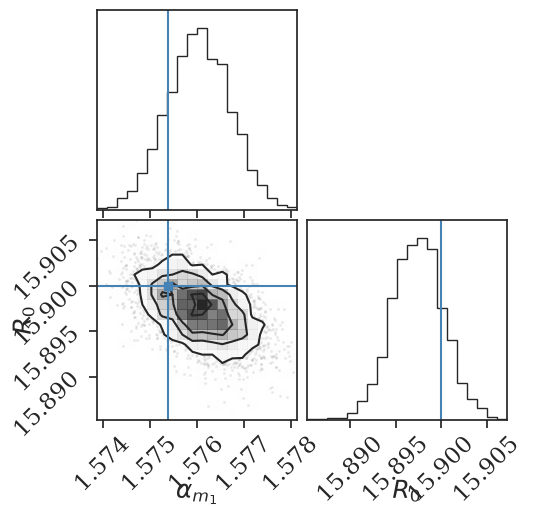

In [46]:
import corner
%pylab inline
corner.corner(np.column_stack([mcmc.get_samples()["alpha_m_1"], mcmc.get_samples()["R0"]]),
                    labels=[r"$\alpha_{m_1}$", r"$R_0$"],
                    truths=[truth["alpha_m_1"], truth["R0"]])
plt.show()

In [44]:
truth["alpha_m_1"]

1.5754

In [31]:
# numpyro_three_populations.py
# NUTS inference of BBH + BNS + NSBH background hyperparameters with FastOmega.
#
#   BBH : bpl_double_gaussian (broken power law + 2 peaks) + madau_dickinson
#   BNS : uniform                                            + madau_dickinson_timedelay
#   NSBH: nsbh_modsmooth                                     + madau_dickinson_timedelay
#
# Free parameters: BBH local rate and redshift evolution (R0, zp, alpha), BNS and
# NSBH local rates.  Masses are fixed (in practice: from the CBC catalogues).
# The noise curve is a TOY (bucket shape rescaled to a chosen SNR); replace sigma
# with a real sensitivity (e.g. from pygwb: PSDs + overlap reduction function).
#
# Speed (Apple M1): one BBH value+gradient ~3.4 ms.  The posterior is not
# Gaussian (zp and alpha are nearly degenerate: the background measures mainly one
# combination), so NUTS needs ~100 leapfrog steps per iteration; three things help:
#   - R0 is a linear factor: Omega = R0 * Omega(R0=1).  Populations whose shape is
#     fixed (here BNS, NSBH) become precomputed templates; BBH is evaluated once
#     with R0=1 per step.                                         (~2-3x)
#   - dense_mass=True learns the parameter correlations.           (~2x)
#   - parallel chains on several cores (set_host_device_count before any JAX work).
#
# Run in the sgwb environment:  python numpyro_three_populations.py
# In Jupyter, copy the body of main() into cells (no __main__ guard needed there);
# numpyro.set_host_device_count must then run in the first cell, before JAX starts.

import time

import numpy as np
import numpyro
numpyro.enable_x64()                       # FastOmega needs float64: call this first
N_CHAINS = 4
numpyro.set_host_device_count(N_CHAINS)    # one CPU "device" per chain (before JAX starts)
import jax
import jax.numpy as jnp
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

from stochaxtic.fast_omega import FastOmega


def main():
    # ------------------------------------------------------------------
    # 1. Omega_GW functions: one table (IMRPhenomXAS, no spins) for all three
    # ------------------------------------------------------------------
    f = np.geomspace(20, 1000, 40)                        # frequency bins [Hz]
    fo = FastOmega(freqs=f, verbose=False)                # table cached in ~/.cache/stochaxtic
    om_bbh  = fo.make("bpl_double_gaussian", "madau_dickinson")
    om_bns  = fo.make("uniform", "madau_dickinson_timedelay")
    om_nsbh = fo.make("nsbh_modsmooth", "madau_dickinson_timedelay")
    # each om_*(mass_params, rate_params) returns Omega_GW(f); parameters not given take
    # their defaults (jax_populations.MASS_MODELS / RATE_DEFAULTS)

    # Omega is linear in R0: shapes of BNS and NSBH are fixed here -> templates at R0 = 1
    T_bns  = np.asarray(om_bns({}, {"R0": 1.0}))
    T_nsbh = np.asarray(om_nsbh({}, {"R0": 1.0}))

    def omega_total(p):
        return (p["R0_bbh"] * om_bbh({}, {"R0": 1.0, "zp": p["zp_bbh"], "alpha": p["alpha_bbh"]})
                + p["R0_bns"] * T_bns + p["R0_nsbh"] * T_nsbh)

    # ------------------------------------------------------------------
    # 2. Mock data: truth + toy Gaussian noise
    # ------------------------------------------------------------------
    truth = dict(R0_bbh=18.0, zp_bbh=2.27, alpha_bbh=2.85, R0_bns=100.0, R0_nsbh=30.0)
    O_true = np.asarray(omega_total(truth))

    shape = (f / 30.0) ** -3 + 1.0 + (f / 30.0) ** 2.5    # toy bucket, minimum near 30 Hz
    snr_target = 50.0
    sigma = shape * np.sqrt(np.sum((O_true / shape) ** 2)) / snr_target
    data = O_true + sigma * np.random.default_rng(1).standard_normal(len(f))

    for name, om, R0 in [("BBH", om_bbh, 18.0), ("BNS", om_bns, 100.0), ("NSBH", om_nsbh, 30.0)]:
        snr = np.sqrt(np.sum((np.asarray(om({}, {"R0": R0})) / sigma) ** 2))
        print(f"{name:5s} SNR = {snr:.1f}")      # BBH ~44, BNS ~3, NSBH ~3

    # ------------------------------------------------------------------
    # 3. numpyro model
    # ------------------------------------------------------------------
    def model(data, catalog=False):
        lnR_bbh  = numpyro.sample("lnR0_bbh",  dist.Uniform(np.log(1), np.log(200)))
        zp       = numpyro.sample("zp_bbh",    dist.Uniform(0.5, 5.0))
        alpha    = numpyro.sample("alpha_bbh", dist.Uniform(0.0, 6.0))
        lnR_bns  = numpyro.sample("lnR0_bns",  dist.Uniform(np.log(5), np.log(2000)))
        lnR_nsbh = numpyro.sample("lnR0_nsbh", dist.Uniform(np.log(1), np.log(500)))
        p = dict(R0_bbh=jnp.exp(lnR_bbh), zp_bbh=zp, alpha_bbh=alpha,
                 R0_bns=jnp.exp(lnR_bns), R0_nsbh=jnp.exp(lnR_nsbh))
        if catalog:
            # stand-in for the resolved-event catalogues: local rates known to
            # ~25% (BBH) and ~60% (BNS, NSBH)
            numpyro.factor("cat_bbh",  dist.Normal(np.log(18.0), 0.25).log_prob(lnR_bbh))
            numpyro.factor("cat_bns",  dist.Normal(np.log(100.0), 0.6).log_prob(lnR_bns))
            numpyro.factor("cat_nsbh", dist.Normal(np.log(30.0), 0.6).log_prob(lnR_nsbh))
        numpyro.sample("obs", dist.Normal(omega_total(p), sigma), obs=data)

    # ------------------------------------------------------------------
    # 4. NUTS: background only, then background + catalogue information
    # ------------------------------------------------------------------
    for catalog in (False, True):
        t = time.time()
        mcmc = MCMC(NUTS(model, target_accept_prob=0.9, dense_mass=True),
                    num_warmup=500, num_samples=1000, num_chains=N_CHAINS,
                    chain_method="parallel", progress_bar=True)
        mcmc.run(jax.random.PRNGKey(0), data, catalog, extra_fields=("num_steps",))
        print("mean leapfrog steps per iteration:",
              float(np.mean(mcmc.get_extra_fields()["num_steps"])))
        print(f"\n=== catalog = {catalog}: {time.time() - t:.0f} s ===")
        mcmc.print_summary()                               # check r_hat ~ 1 and n_eff
        samples = mcmc.get_samples()
        np.savez(f"samples_catalog{int(catalog)}.npz", **{k: np.asarray(v) for k, v in samples.items()})



In [32]:
main()

BBH   SNR = 43.9
BNS   SNR = 3.4
NSBH  SNR = 2.8


/var/folders/s8/hcf014fx4_nbjzv0fgjh_04m0000gn/T/ipykernel_14218/705371562.py:100: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(NUTS(model, target_accept_prob=0.9, dense_mass=True),
sample: 100%|██████████| 1500/1500 [11:10<00:00,  2.24it/s, 255 steps of size 9.30e-03. acc. prob=0.97] 


mean leapfrog steps per iteration: 190.3265

=== catalog = False: 3946 s ===

                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  alpha_bbh      2.44      1.52      2.32      0.04      4.63    484.48      1.02
   lnR0_bbh      2.34      1.37      2.32      0.01      4.24   1008.99      1.01
   lnR0_bns      4.64      1.62      4.82      2.20      7.24   1339.83      1.01
  lnR0_nsbh      3.95      1.85      4.40      1.06      6.21    902.45      1.00
     zp_bbh      2.67      1.25      2.63      0.80      4.72   1151.27      1.00

Number of divergences: 84


/var/folders/s8/hcf014fx4_nbjzv0fgjh_04m0000gn/T/ipykernel_14218/705371562.py:100: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(NUTS(model, target_accept_prob=0.9, dense_mass=True),
sample: 100%|██████████| 1500/1500 [06:58<00:00,  3.58it/s, 255 steps of size 1.77e-02. acc. prob=0.97]

mean leapfrog steps per iteration: 137.48675

=== catalog = True: 1112 s ===

                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  alpha_bbh      2.83      0.87      2.56      1.63      4.25    219.22      1.01
   lnR0_bbh      2.91      0.25      2.91      2.52      3.32   2035.58      1.00
   lnR0_bns      4.59      0.61      4.60      3.61      5.60   2204.91      1.00
  lnR0_nsbh      3.47      0.59      3.46      2.47      4.40   2772.81      1.00
     zp_bbh      2.87      1.25      2.91      1.07      4.99    328.26      1.00

Number of divergences: 25


In [2]:
data = np.load("samples_catalog0.npz")

In [3]:
data.files

['alpha_bbh', 'lnR0_bbh', 'lnR0_bns', 'lnR0_nsbh', 'zp_bbh']

In [7]:
post = np.column_stack([data["alpha_bbh"], data["lnR0_bbh"], data['lnR0_bns'], data['lnR0_nsbh'], data['zp_bbh']])

In [11]:
truth = {'lnR0_bbh': np.log(18.0), 'zp_bbh': 2.27, 'alpha_bbh': 2.85, 'lnR0_bns': np.log(100.0), 'lnR0_nsbh':np.log(30.0)}

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


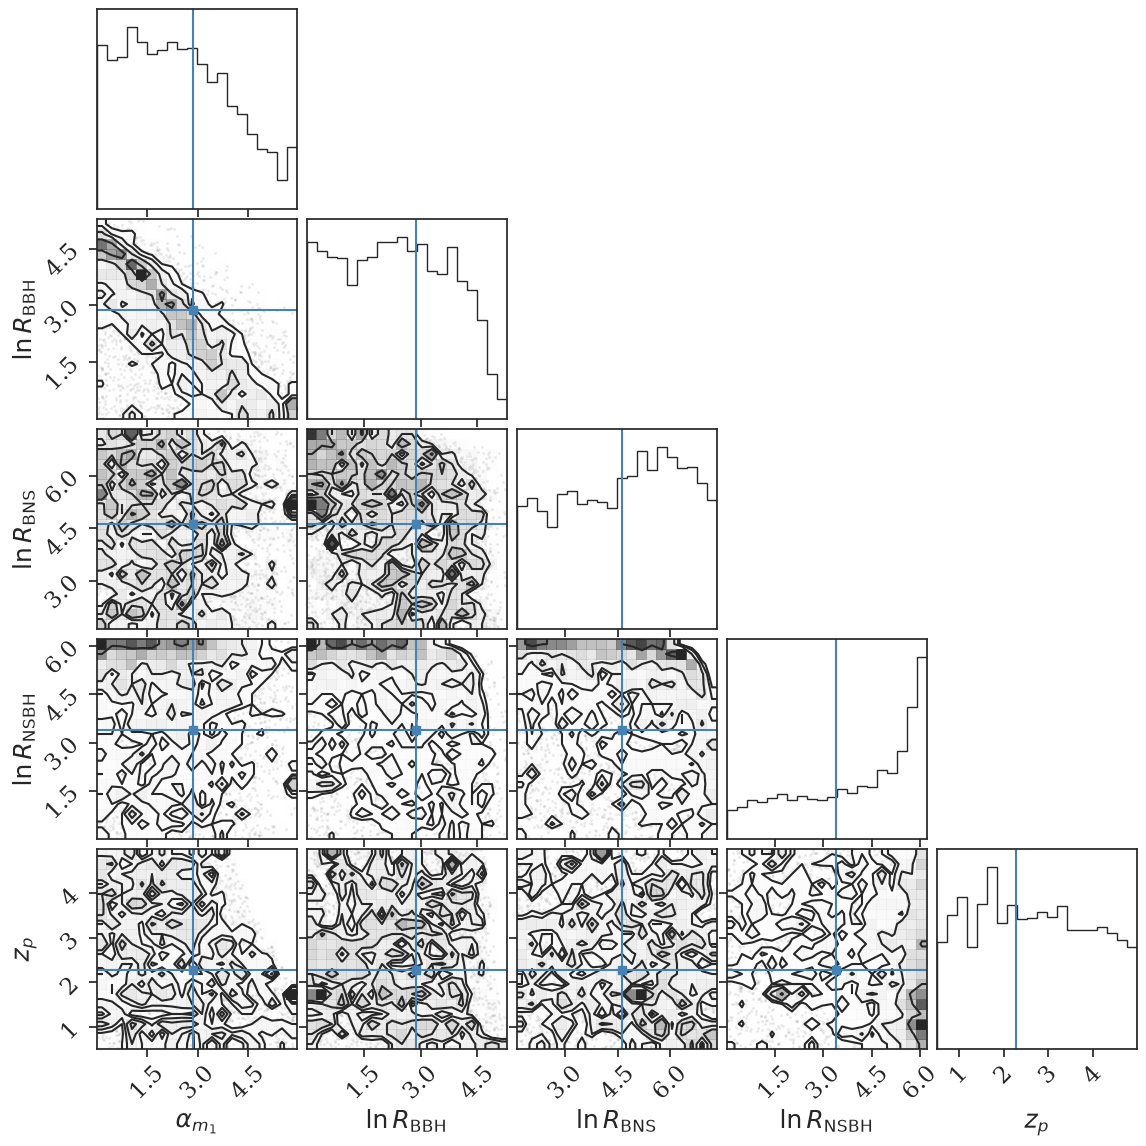

In [13]:
import corner
%pylab inline
corner.corner(post,
            labels=[r"$\alpha_{m_1}$", r"$\ln R_\mathrm{BBH}$",r"$\ln R_\mathrm{BNS}$", r"$\ln R_\mathrm{NSBH}$", r"$z_p$"],
            truths=[truth["alpha_bbh"], truth["lnR0_bbh"], truth["lnR0_bns"], truth["lnR0_nsbh"], truth["zp_bbh"]])
plt.show()

In [2]:
PopFisher = np.load("/Users/haowenzhong/opencode/GWFAST_study/popfisher_CESTMworst_BNS_cosmo/fisher_bundle_CE40ET2L_hAp_5hz.npz")

In [5]:
PopFisher['Gamma_lnR0'], PopFisher['names_lnR0']

(array([[ 5617.18864334,  3525.60000888,  -198.79826482,  3199.44639106,
          3756.87192789],
        [ 3525.60000888, 33753.41710232,  -637.85724758, 25493.00982411,
         38623.45661432],
        [ -198.79826482,  -637.85724758,   418.55356083, -2284.04594651,
          -269.64297132],
        [ 3199.44639106, 25493.00982411, -2284.04594651, 28097.42447575,
         27081.27540274],
        [ 3756.87192789, 38623.45661432,  -269.64297132, 27081.27540274,
         47197.50753748]]),
 array(['alpha_m', 'alpha_z', 'beta_z', 'zp', 'ln_R0'], dtype='<U7'))

In [14]:
truth = PopFisher['theta_star_lnR0'][1:]

In [15]:
Cov = np.linalg.inv(PopFisher['Gamma_lnR0'][1:, 1:])
Samps = np.random.default_rng(1).multivariate_normal(mean=truth, cov=Cov, size=4000)

In [ ]:
# alpha_z, beta_z, zp, ln_R0
Samps

array([[1.84963924, 3.53561032, 1.82956796, 4.34654442],
       [1.85141038, 3.6253865 , 1.85574913, 4.33802817],
       [1.86680903, 3.5402965 , 1.83224869, 4.33878524],
       ...,
       [1.87846063, 3.40394927, 1.80505524, 4.34201524],
       [1.84441374, 3.66187079, 1.85659333, 4.34270179],
       [1.86900155, 3.68653566, 1.86409939, 4.31933642]])

In [20]:
import time, numpy as np, jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
numpyro.enable_x64()
from stochaxtic.fast_omega import FastOmega

/Users/haowenzhong/miniforge3/envs/sgwb/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [44]:
freqs = np.geomspace(5, 1024, 1000)
fo_XAS = FastOmega(freqs=freqs, m_tot_range=(6, 700), waveform="IMRPhenomXAS")
fo_XPHM = FastOmega(freqs=freqs, m_tot_range=(6, 700), waveform="IMRPhenomXPHM")

FastOmega: table loaded from /Users/haowenzhong/.cache/stochaxtic/jtable_IMRPhenomXAS_e9d708d5273bb246.npz
FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 12; grids lnM 953, z 444, lnq 121, lnf 1066; setup 0.1 s
FastOmega: building the IMRPhenomXPHM table: 121 spin/q columns x 1 kappa nodes, 866 frequencies each ...
FastOmega: table built in 6 s, cached at /Users/haowenzhong/.cache/stochaxtic/jtable_IMRPhenomXPHM_f0aa158493d824d4.npz
FastOmega: IMRPhenomXPHM, spins=None, tides=False: 121 table columns, rank 15; grids lnM 953, z 444, lnq 121, lnf 1066; setup 6.6 s


In [57]:
fo_F2 = FastOmega(freqs=freqs, m_tot_range=(6, 700), waveform="TaylorF2")
fo_D = FastOmega(freqs=freqs, m_tot_range=(6, 700), waveform="IMRPhenomD")

FastOmega: table loaded from /Users/haowenzhong/.cache/stochaxtic/jtable_TaylorF2_38e6234508f3db73.npz
FastOmega: TaylorF2, spins=None, tides=False: 121 table columns, rank 12; grids lnM 953, z 444, lnq 121, lnf 1066; setup 0.8 s
FastOmega: building the IMRPhenomD table: 121 spin/q columns x 1 kappa nodes, 866 frequencies each ...
FastOmega: table built in 0 s, cached at /Users/haowenzhong/.cache/stochaxtic/jtable_IMRPhenomD_9f6a4da03e77b9d2.npz
FastOmega: IMRPhenomD, spins=None, tides=False: 121 table columns, rank 12; grids lnM 953, z 444, lnq 121, lnf 1066; setup 0.7 s


In [58]:
omega_XAS   = fo_XAS.make("uniform", "madau_dickinson")        # jitted 单个 Λ → Ω(f)
omega_XPHM   = fo_XPHM.make("uniform", "madau_dickinson")        # jitted 单个 Λ → Ω(f)
omega_F2   = fo_F2.make("uniform", "madau_dickinson")        # jitted 单个 Λ → Ω(f)
omega_D    = fo_D.make("uniform", "madau_dickinson")        # jitted 单个 Λ → Ω(f)

/Users/haowenzhong/Claudecode/SGWB_toolbox/StochAXtic/stochaxtic/fast_omega.py:506: UserWarning: FastOmega: 100.00% of the uniform population lies outside the grid (M < 5.99: 100.00%, M > 702: 0.00%, q < 0.01: 0.00%) and is dropped; widen m_tot_range / q_min
  self.check_support(mass, None, n_sub)                 # warns if the defaults leak out
/Users/haowenzhong/Claudecode/SGWB_toolbox/StochAXtic/stochaxtic/fast_omega.py:506: UserWarning: FastOmega: 100.00% of the uniform population lies outside the grid (M < 5.99: 100.00%, M > 702: 0.00%, q < 0.01: 0.00%) and is dropped; widen m_tot_range / q_min
  self.check_support(mass, None, n_sub)                 # warns if the defaults leak out
/Users/haowenzhong/Claudecode/SGWB_toolbox/StochAXtic/stochaxtic/fast_omega.py:506: UserWarning: FastOmega: 100.00% of the uniform population lies outside the grid (M < 5.99: 100.00%, M > 702: 0.00%, q < 0.01: 0.00%) and is dropped; widen m_tot_range / q_min
  self.check_support(mass, None, n_sub)      

In [26]:
# alpha_z, beta_z, zp, ln_R0
Samps

array([[1.84963924, 3.53561032, 1.82956796, 4.34654442],
       [1.85141038, 3.6253865 , 1.85574913, 4.33802817],
       [1.86680903, 3.5402965 , 1.83224869, 4.33878524],
       ...,
       [1.87846063, 3.40394927, 1.80505524, 4.34201524],
       [1.84441374, 3.66187079, 1.85659333, 4.34270179],
       [1.86900155, 3.68653566, 1.86409939, 4.31933642]])

In [59]:
import jax
import jax.numpy as jnp

def batched_omega_XAS(alpha_z, beta_z, zp, ln_R0, batch_size=200):
    def one(a, b, z, lr):
        # 在 jit/vmap 里必须用 jnp，np.exp 碰到 tracer 会报错
        return omega_XAS(rate_params={"alpha": a, "beta": b, "zp": z, "R0": jnp.exp(lr)})

    params = jnp.stack([alpha_z, beta_z, zp, ln_R0], axis=-1)   # (n, 4)
    n = params.shape[0]

    # n 不能被 batch_size 整除时，用最后一行补齐，算完再切掉
    n_pad = (-n) % batch_size
    if n_pad:
        params = jnp.concatenate([params, jnp.repeat(params[-1:], n_pad, axis=0)], axis=0)

    pb = params.reshape(-1, batch_size, 4)                      # (n_batch, batch_size, 4)
    out = jax.lax.map(lambda p: jax.vmap(one)(p[:, 0], p[:, 1], p[:, 2], p[:, 3]), pb)
    return out.reshape(-1, out.shape[-1])[:n]                   # (n, n_freq)

batched_XAS = jax.jit(batched_omega_XAS, static_argnames="batch_size")

def batched_omega_XPHM(alpha_z, beta_z, zp, ln_R0, batch_size=200):
    def one(a, b, z, lr):
        # 在 jit/vmap 里必须用 jnp，np.exp 碰到 tracer 会报错
        return omega_XPHM(rate_params={"alpha": a, "beta": b, "zp": z, "R0": jnp.exp(lr)})

    params = jnp.stack([alpha_z, beta_z, zp, ln_R0], axis=-1)   # (n, 4)
    n = params.shape[0]

    # n 不能被 batch_size 整除时，用最后一行补齐，算完再切掉
    n_pad = (-n) % batch_size
    if n_pad:
        params = jnp.concatenate([params, jnp.repeat(params[-1:], n_pad, axis=0)], axis=0)

    pb = params.reshape(-1, batch_size, 4)                      # (n_batch, batch_size, 4)
    out = jax.lax.map(lambda p: jax.vmap(one)(p[:, 0], p[:, 1], p[:, 2], p[:, 3]), pb)
    return out.reshape(-1, out.shape[-1])[:n]                   # (n, n_freq)

def batched_omega_F2(alpha_z, beta_z, zp, ln_R0, batch_size=200):
    def one(a, b, z, lr):
        # 在 jit/vmap 里必须用 jnp，np.exp 碰到 tracer 会报错
        return omega_F2(rate_params={"alpha": a, "beta": b, "zp": z, "R0": jnp.exp(lr)})

    params = jnp.stack([alpha_z, beta_z, zp, ln_R0], axis=-1)   # (n, 4)
    n = params.shape[0]

    # n 不能被 batch_size 整除时，用最后一行补齐，算完再切掉
    n_pad = (-n) % batch_size
    if n_pad:
        params = jnp.concatenate([params, jnp.repeat(params[-1:], n_pad, axis=0)], axis=0)

    pb = params.reshape(-1, batch_size, 4)                      # (n_batch, batch_size, 4)
    out = jax.lax.map(lambda p: jax.vmap(one)(p[:, 0], p[:, 1], p[:, 2], p[:, 3]), pb)
    return out.reshape(-1, out.shape[-1])[:n]                   # (n, n_freq)

def batched_omega_D(alpha_z, beta_z, zp, ln_R0, batch_size=200):
    def one(a, b, z, lr):
        # 在 jit/vmap 里必须用 jnp，np.exp 碰到 tracer 会报错
        return omega_D(rate_params={"alpha": a, "beta": b, "zp": z, "R0": jnp.exp(lr)})

    params = jnp.stack([alpha_z, beta_z, zp, ln_R0], axis=-1)   # (n, 4)
    n = params.shape[0]

    # n 不能被 batch_size 整除时，用最后一行补齐，算完再切掉
    n_pad = (-n) % batch_size
    if n_pad:
        params = jnp.concatenate([params, jnp.repeat(params[-1:], n_pad, axis=0)], axis=0)

    pb = params.reshape(-1, batch_size, 4)                      # (n_batch, batch_size, 4)
    out = jax.lax.map(lambda p: jax.vmap(one)(p[:, 0], p[:, 1], p[:, 2], p[:, 3]), pb)
    return out.reshape(-1, out.shape[-1])[:n]                   # (n, n_freq)

batched_XAS = jax.jit(batched_omega_XAS, static_argnames="batch_size")
batched_XPHM = jax.jit(batched_omega_XPHM, static_argnames="batch_size")
batched_F2 = jax.jit(batched_omega_F2, static_argnames="batch_size")
batched_D = jax.jit(batched_omega_D, static_argnames="batch_size")
S = jnp.asarray(Samps)
Om_XAS = batched_XAS(S[:, 0], S[:, 1], S[:, 2], S[:, 3], batch_size=200)   # (4000, 400)
Om_XAS.block_until_ready()

Om_XPHM = batched_XPHM(S[:, 0], S[:, 1], S[:, 2], S[:, 3], batch_size=200)   # (4000, 400)
Om_XPHM.block_until_ready()

Om_F2 = batched_F2(S[:, 0], S[:, 1], S[:, 2], S[:, 3], batch_size=200)   # (4000, 400)
Om_F2.block_until_ready()

Om_D = batched_D(S[:, 0], S[:, 1], S[:, 2], S[:, 3], batch_size=200)   # (4000, 400)
Om_D.block_until_ready()

Array([[3.51592471e-11, 3.52819929e-11, 3.54051577e-11, ...,
        9.55160842e-10, 9.57777756e-10, 9.60347463e-10],
       [3.52209694e-11, 3.53439368e-11, 3.54673242e-11, ...,
        9.60668886e-10, 9.63283494e-10, 9.65849468e-10],
       [3.54000504e-11, 3.55236308e-11, 3.56476331e-11, ...,
        9.60101635e-10, 9.62686559e-10, 9.65223498e-10],
       ...,
       [3.55655576e-11, 3.56896957e-11, 3.58142575e-11, ...,
        9.55453609e-10, 9.57982101e-10, 9.60463976e-10],
       [3.51781315e-11, 3.53009569e-11, 3.54242019e-11, ...,
        9.62608317e-10, 9.65260958e-10, 9.67864754e-10],
       [3.51272419e-11, 3.52498830e-11, 3.53729429e-11, ...,
        9.59918668e-10, 9.62498373e-10, 9.65028392e-10]], dtype=float64)

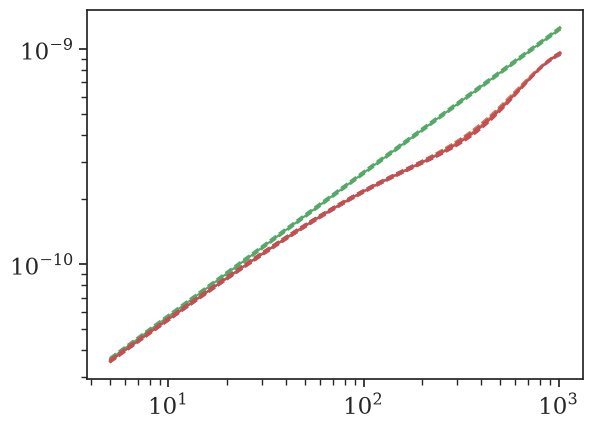

In [60]:
plt.loglog(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=50), color="C0", alpha=1)
plt.loglog(fo_XAS.freqs, np.percentile(Om_XPHM, axis=0, q=50), color="C1", alpha=1)

plt.loglog(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=5), color="C0", alpha=1, linestyle="--")
plt.loglog(fo_XAS.freqs, np.percentile(Om_XPHM, axis=0, q=5), color="C1", alpha=1, linestyle="--")

plt.loglog(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=95), color="C0", alpha=1, linestyle="--")
plt.loglog(fo_XAS.freqs, np.percentile(Om_XPHM, axis=0, q=95), color="C1", alpha=1, linestyle="--")

plt.loglog(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=50), color="C2", alpha=1)
plt.loglog(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=5), color="C2", alpha=1, linestyle="--")
plt.loglog(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=95), color="C2", alpha=1, linestyle="--")

plt.loglog(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=50), color="C3", alpha=1)
plt.loglog(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=5), color="C3", alpha=1, linestyle="--")
plt.loglog(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=95), color="C3", alpha=1, linestyle="--")

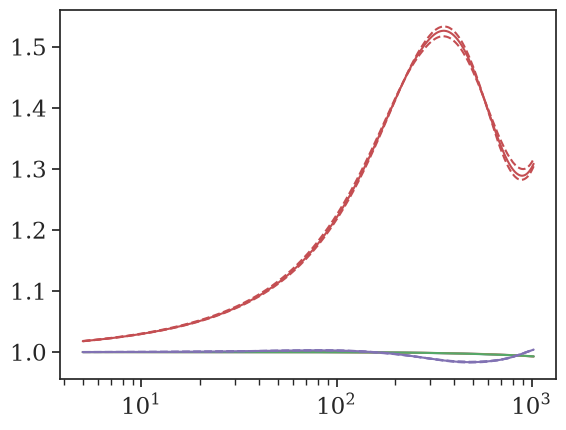

In [61]:
plt.semilogx(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=50)/np.percentile(Om_XPHM, axis=0, q=50), color="C0", alpha=1)
plt.semilogx(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=5)/np.percentile(Om_XPHM, axis=0, q=5), color="C1", alpha=1)
plt.semilogx(fo_XAS.freqs, np.percentile(Om_XAS, axis=0, q=95)/np.percentile(Om_XPHM, axis=0, q=95), color="C2", alpha=1)
plt.semilogx(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=50)/np.percentile(Om_XPHM, axis=0, q=50), color="C3", alpha=1)
plt.semilogx(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=5)/np.percentile(Om_XPHM, axis=0, q=5), color="C3", alpha=1, linestyle="--")
plt.semilogx(fo_XAS.freqs, np.percentile(Om_F2, axis=0, q=95)/np.percentile(Om_XPHM, axis=0, q=95), color="C3", alpha=1, linestyle="--")
plt.semilogx(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=50)/np.percentile(Om_XPHM, axis=0, q=50), color="C4", alpha=1)
plt.semilogx(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=5)/np.percentile(Om_XPHM, axis=0, q=5), color="C4", alpha=1, linestyle="--")
plt.semilogx(fo_XAS.freqs, np.percentile(Om_D, axis=0, q=95)/np.percentile(Om_XPHM, axis=0, q=95), color="C4", alpha=1, linestyle="--")

<Axes: ylabel='Count'>

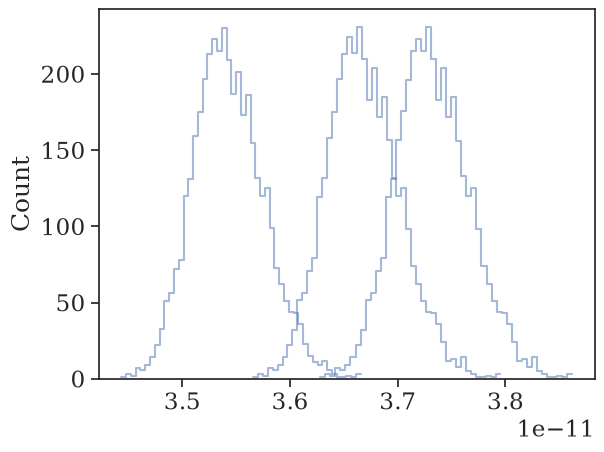

In [72]:
sns.histplot(Om_XAS[:, 0], bins=50, element="step", color="C0", alpha=0.5, fill=False, label="XAS")
sns.histplot(Om_XAS[:, 10], bins=50, element="step", color="C0", alpha=0.5, fill=False, label="XAS")
sns.histplot(Om_XAS[:, 15], bins=50, element="step", color="C0", alpha=0.5, fill=False, label="XAS")

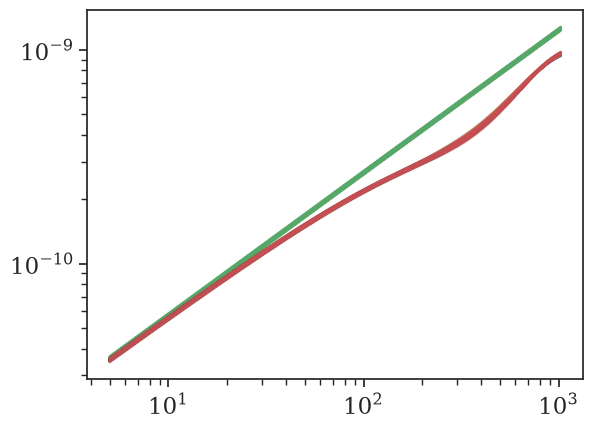

In [62]:
for i in range(400):
    plt.loglog(fo.freqs, Om_XAS[i, :], color="C0", alpha=0.1)

for i in range(400):
    plt.loglog(fo.freqs, Om_XPHM[i, :], color="C1", alpha=0.1)

for i in range(400):
    plt.loglog(fo.freqs, Om_F2[i, :], color="C2", alpha=0.1)

for i in range(400):
    plt.loglog(fo.freqs, Om_D[i, :], color="C3", alpha=0.1)
